## Remove or transform extreme outliers by implementing multiple outlier-handling strategies, such as Winsorization and log transformations, and justify the chosen method with a comparative analysis. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('heart.csv')                     
X, y = df.drop(columns='target'), df['target'].values
names = list(X.columns)
num = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']      
ni = [names.index(c) for c in num]                         
X = X.values.astype(float)
print(X.shape)

(303, 13)


In [2]:
def fences(a):
    q1, q3 = np.percentile(a, [25, 75], axis=0); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

def skewness(a):
    z = (a - a.mean(0)) / a.std(0)
    return (z ** 3).mean(0)

lo, hi = fences(X[:, ni]); z = (X[:, ni] - X[:, ni].mean(0)) / X[:, ni].std(0)
report = pd.DataFrame({'min': X[:, ni].min(0), 'max': X[:, ni].max(0), 'skew': skewness(X[:, ni]),
                       'IQR outliers': ((X[:, ni] < lo) | (X[:, ni] > hi)).sum(0),
                       '|z|>3 outliers': (abs(z) > 3).sum(0)}, index=num)
report.round(2)

,min,max,skew,IQR outliers,|z|>3 outliers
age,29.0,77.0,-0.20,0,0
trestbps,94.0,200.0,0.71,9,2
chol,126.0,564.0,1.14,5,4
thalach,71.0,202.0,-0.53,1,1
oldpeak,0.0,6.2,1.26,5,2


Rows with any outlier: 19 of 303 (6.3%)
Target=1 rate in outlier rows: 0.32 | in other rows: 0.56


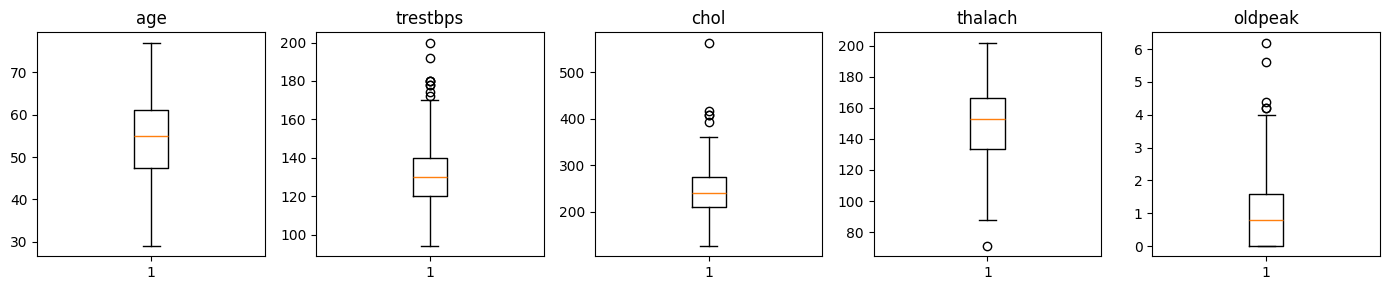

In [3]:
is_out = ((X[:, ni] < lo) | (X[:, ni] > hi)).any(1)
print('Rows with any outlier:', is_out.sum(), 'of', len(X), f'({is_out.mean():.1%})')
print('Target=1 rate in outlier rows:', y[is_out].mean().round(2), '| in other rows:', y[~is_out].mean().round(2))

fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for a, c, j in zip(ax, num, ni): a.boxplot(X[:, j]); a.set_title(c)
plt.tight_layout(); plt.show()

In [4]:
def clip(A, lo, hi):
    A = A.copy(); A[:, ni] = np.clip(A[:, ni], lo, hi); return A

def s_none(Xtr, ytr, Xte):
    return Xtr, ytr, Xte

def s_remove(Xtr, ytr, Xte):                                 
    lo, hi = fences(Xtr[:, ni]); keep = ((Xtr[:, ni] >= lo) & (Xtr[:, ni] <= hi)).all(1)
    return Xtr[keep], ytr[keep], Xte

def s_wins_iqr(Xtr, ytr, Xte):
    lo, hi = fences(Xtr[:, ni]); return clip(Xtr, lo, hi), ytr, clip(Xte, lo, hi)

def s_wins_pct(Xtr, ytr, Xte):
    lo, hi = np.percentile(Xtr[:, ni], [5, 95], axis=0); return clip(Xtr, lo, hi), ytr, clip(Xte, lo, hi)

def s_log(Xtr, ytr, Xte):                                    
    cols = [j for j, s in zip(ni, skewness(Xtr[:, ni])) if s > 0.5]
    A, B = Xtr.copy(), Xte.copy(); A[:, cols] = np.log1p(A[:, cols]); B[:, cols] = np.log1p(B[:, cols])
    return A, ytr, B

strategies = {'None': s_none, 'Remove (IQR)': s_remove, 'Winsorize (IQR)': s_wins_iqr,
              'Winsorize (5-95%)': s_wins_pct, 'Log1p (skewed cols)': s_log}

In [5]:
def count_outliers(A):
    l, h = fences(A[:, ni]); return int(((A[:, ni] < l) | (A[:, ni] > h)).sum())

rows = []
for name, f in strategies.items():
    A, _, _ = f(X, y, X)
    rows.append((name, len(A), np.abs(skewness(A[:, ni])).mean(), count_outliers(A)))
A = X.copy(); A[:, ni] = np.log1p(A[:, ni])                   
rows.append(('Log1p (ALL 5 cols)', len(A), np.abs(skewness(A[:, ni])).mean(), count_outliers(A)))
pd.DataFrame(rows, columns=['Strategy', 'Rows kept', 'Mean |skew|', 'Outliers left']).round(3)

,Strategy,Rows kept,Mean |skew|,Outliers left
0,None,303,0.770,20
1,Remove (IQR),284,0.402,0
2,Winsorize (IQR),303,0.480,0
3,Winsorize (5-95%),303,0.400,0
4,Log1p (skewed cols),303,0.301,16
5,Log1p (ALL 5 cols),303,0.466,22


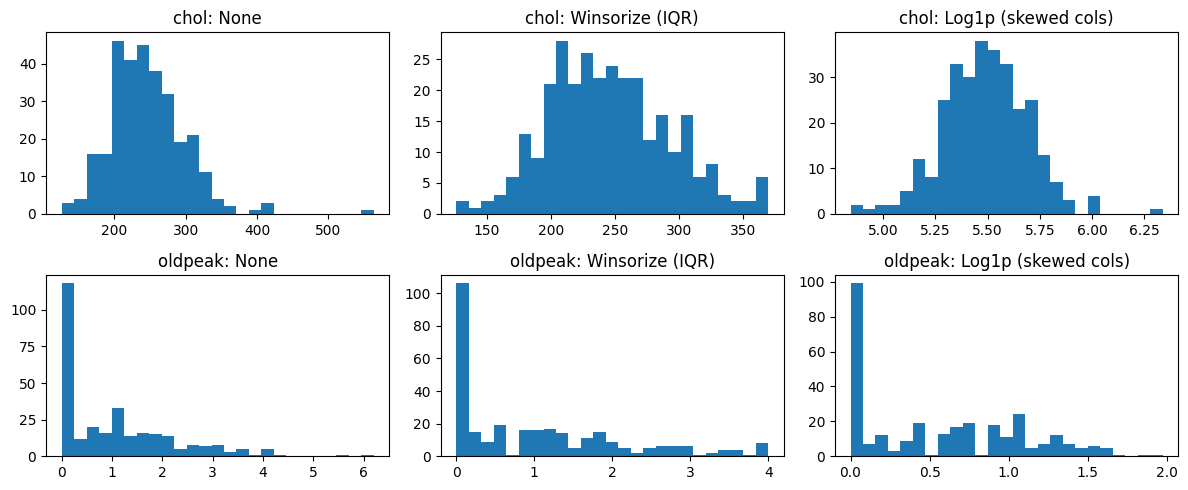

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(12, 5))
for r, c in enumerate(['chol', 'oldpeak']):
    j = names.index(c)
    for k, (name, f) in enumerate([('None', s_none), ('Winsorize (IQR)', s_wins_iqr), ('Log1p (skewed cols)', s_log)]):
        ax[r, k].hist(f(X, y, X)[0][:, j], bins=25, color='tab:blue'); ax[r, k].set_title(f'{c}: {name}')
plt.tight_layout(); plt.show()

In [7]:
def fit_logreg(A, t, lr=0.1, iters=800):
    w, b = np.zeros(A.shape[1]), 0.0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-(A @ w + b)))
        w -= lr * A.T @ (p - t) / len(t); b -= lr * np.mean(p - t)
    return w, b

def scores(t, pred):
    tp, fp, fn = np.sum((pred == 1) & (t == 1)), np.sum((pred == 1) & (t == 0)), np.sum((pred == 0) & (t == 1))
    return np.mean(pred == t), 2 * tp / max(2 * tp + fp + fn, 1)       # accuracy, F1

In [8]:
results = {n: [] for n in strategies}
for rep in range(5):
    perm = np.random.default_rng(rep).permutation(len(X)); folds = np.array_split(perm, 5)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        for name, f in strategies.items():
            Xa, ya, Xb = f(X[tr], y[tr], X[te])
            mu, sd = Xa.mean(0), Xa.std(0) + 1e-9                        
            w, b = fit_logreg((Xa - mu) / sd, ya)
            pred = ((((Xb - mu) / sd) @ w + b) > 0).astype(int)
            results[name].append(scores(y[te], pred))

base = np.array(results['None'])
print(f"{'Strategy':20s} {'Accuracy':>15s} {'F1':>15s} {'Acc diff vs None (paired)':>27s}")
for name, r in results.items():
    r = np.array(r); d = r[:, 0] - base[:, 0]                          
    print(f"{name:20s} {r[:,0].mean():.3f} +- {r[:,0].std():.3f}   {r[:,1].mean():.3f} +- {r[:,1].std():.3f}   "
          f"{d.mean():+.3f} +- {d.std(ddof=1) / np.sqrt(len(d)):.3f}")

Strategy                    Accuracy              F1   Acc diff vs None (paired)
None                 0.821 +- 0.048   0.843 +- 0.042   +0.000 +- 0.000
Remove (IQR)         0.823 +- 0.053   0.843 +- 0.047   +0.002 +- 0.004
Winsorize (IQR)      0.826 +- 0.051   0.848 +- 0.044   +0.005 +- 0.003
Winsorize (5-95%)    0.826 +- 0.050   0.847 +- 0.043   +0.005 +- 0.004
Log1p (skewed cols)  0.823 +- 0.050   0.845 +- 0.043   +0.002 +- 0.003
